# **Project Name**    - Amazon Prime Video TV Shows & Movies: Exploratory Data Analysis

##### **Project Type**    - EDA+Regression
##### **Contribution**    - Individual
##### **Member -**   - Rachana F Patil

# **Project Summary -**

The project “Amazon Prime TV Shows and Movies Analysis” focuses on exploring and analysing the content available on Amazon Prime Video using data analysis, statistical techniques, data visualization, and machine learning. The primary objective is to understand the characteristics of the platform's content catalogue, identify patterns and trends, and examine the factors associated with the popularity and ratings of movies and television shows. The analysis aims to transform raw dataset information into meaningful insights that can support better understanding of content distribution, audience preferences, and catalogue characteristics.

The project uses two datasets: a titles dataset and a credits dataset. The titles dataset contains information about movies and television shows, including title ID, title name, show type, description, release year, age certification, runtime, genres, production countries, number of seasons, IMDb ID, IMDb score, IMDb votes, TMDB popularity, and TMDB score. The credits dataset contains information about the individuals associated with each title, including person ID, title ID, name, character name, and role. These datasets provide complementary information, allowing the analysis to consider both content-related attributes and the people involved in producing or appearing in the titles.

The initial stage of the project involves understanding the datasets through data inspection and profiling. This includes examining the structure, dimensions, column names, data types, statistical summaries, and sample records. Data quality is assessed by identifying missing values, duplicate records, inconsistent entries, and other potential issues. Data cleaning and preprocessing techniques are then applied to improve data consistency and prepare the information for further analysis. Since the credits dataset may contain multiple individuals associated with a single title, appropriate handling of the relationship between the two datasets is necessary to avoid unintended duplication during analysis.

Exploratory Data Analysis (EDA) is performed to investigate different aspects of the Amazon Prime catalogue. Univariate analysis is used to understand individual variables, such as the distribution of release years, show types, runtimes, genres, and ratings. Bivariate and multivariate analysis is used to explore relationships between variables, including the association between release year and content availability, differences between movies and television shows, genre distribution across production countries, and relationships between IMDb ratings, votes, and popularity. Various visualizations, including bar charts, histograms, box plots, count plots, scatter plots, heatmaps, and other suitable charts, are used to communicate these patterns effectively.

The project also incorporates statistical hypothesis testing to examine selected relationships and determine whether observed differences or associations are statistically significant. Following exploratory analysis, machine learning techniques are applied to investigate whether selected content attributes can be used to predict an appropriate target variable. This stage involves feature selection, feature engineering, data preprocessing, model training, and evaluation using suitable performance metrics. Multiple models may be compared to identify an approach that performs appropriately on the available data.

Overall, this project combines data analytics and machine learning to develop a structured understanding of Amazon Prime Video's content catalogue. It aims to identify meaningful patterns in content types, genres, production regions, release trends, and audience ratings. The resulting analysis can help highlight catalogue characteristics, provide insights into content diversity, and demonstrate how data-driven techniques can support decision-making in digital entertainment platforms. The project also provides practical experience in handling real-world datasets, performing statistical analysis, creating informative visualizations, and developing machine learning workflows.

# **GitHub Link -**

https://github.com/RachanaFPatil/Amazon-Prime-Video-TV-Shows-and-Movies-Predicting-Highly-Rated-Titles

# **Problem Statement**


**Amazon Prime Video keeps expanding its library of shows and movies, but without data-driven analysis it is hard to know what the catalogue contains, how it has changed, and what audiences rate highly. This project analyses two datasets, `titles` (title-level metadata, ratings and popularity) and `credits` (actors and directors per title), to answer four questions:**

1. **Content Diversity:** Which genres and categories dominate the platform?
2. **Regional Availability:** How does content distribution vary across production countries?
3. **Trends Over Time:** How has the content library evolved by release year and decade?
4. **IMDb Ratings & Popularity:** What are the highest-rated and most popular titles, and what is associated with a high rating?

#### **Define Your Business Objective?**

To turn the Amazon Prime catalogue and credits data into actionable insights that help content strategy and investment decisions: understand the genre, type and country mix; identify how the library has grown and changed over time; and find which characteristics (type, genre, runtime, age certification, cast and director presence) are associated with high IMDb ratings and popularity. These insights can guide content acquisition, regional targeting and audience engagement.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import ast, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

### Dataset Loading

In [2]:
# Load Dataset
#  read the CSV files
titles = pd.read_csv('C:\\Users\\User\\Downloads\\Amazon EDA\\titles.csv')
credits = pd.read_csv('C:\\Users\\User\\Downloads\\Amazon EDA\\credits.csv')

try:
    titles, credits
    print("Using existing variables: titles, credits")
except NameError:
    titles = pd.read_csv("titles.csv")
    credits = pd.read_csv("credits.csv")
    print("Loaded from titles.csv and credits.csv")

print("titles :", titles.shape, "| credits:", credits.shape)

Using existing variables: titles, credits
titles : (9871, 15) | credits: (124235, 5)


### Dataset First View

In [3]:
# Dataset First Look
print("=== TITLES: first 5 rows ===")
display(titles.head())
print("\n=== TITLES: last 5 rows ===")
display(titles.tail())
print("\n=== CREDITS: first 5 rows ===")
display(credits.head())
print("\n=== CREDITS: last 5 rows ===")
display(credits.tail())

=== TITLES: first 5 rows ===


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,NaN,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],NaN,tt0017925,8.2,89766.0,8.647,8.0
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,NaN,171,"['romance', 'war', 'drama']",['US'],NaN,tt0036868,8.1,63026.0,8.435,7.8
3,tm83884,His Girl Friday,MOVIE,"Hildy, the journalist former wife of newspaper...",1940,NaN,92,"['comedy', 'drama', 'romance']",['US'],NaN,tt0032599,7.8,57835.0,11.270,7.4
4,tm56584,In a Lonely Place,MOVIE,An aspiring actress begins to suspect that her...,1950,NaN,94,"['thriller', 'drama', 'romance']",['US'],NaN,tt0042593,7.9,30924.0,8.273,7.6



=== TITLES: last 5 rows ===


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score
9866,tm510327,Lily Is Here,MOVIE,Dallas and heroin have one thing in common: Du...,2021,NaN,93,['drama'],['US'],NaN,tt7672388,5.3,20.0,1.406,NaN
9867,tm1079144,Jay Nog: Something from Nothing,MOVIE,Something From Nothing takes you on a stand-up...,2021,NaN,55,['comedy'],['US'],NaN,tt15041600,NaN,NaN,0.600,NaN
9868,tm847725,Chasing,MOVIE,A cop from Chennai sets out to nab a dreaded d...,2021,NaN,116,['crime'],['IN'],NaN,NaN,NaN,NaN,1.960,NaN
9869,tm1054116,Baikunth,MOVIE,"This story is about prevalent caste problem, e...",2021,NaN,72,"['family', 'drama']",[],NaN,tt14331982,8.4,49.0,0.645,NaN
9870,ts275838,Waking Up Eighty,SHOW,"Kara Stewart, 16, is fed up with just about ev...",2021,NaN,10,['drama'],[],1.0,tt13542552,NaN,NaN,NaN,NaN



=== CREDITS: first 5 rows ===


,person_id,id,name,character,role
0,59401,ts20945,Joe Besser,Joe,ACTOR
1,31460,ts20945,Moe Howard,Moe,ACTOR
2,31461,ts20945,Larry Fine,Larry,ACTOR
3,21174,tm19248,Buster Keaton,Johnny Gray,ACTOR
4,28713,tm19248,Marion Mack,Annabelle Lee,ACTOR



=== CREDITS: last 5 rows ===


,person_id,id,name,character,role
124230,1938589,tm1054116,Sangam Shukla,Madhav,ACTOR
124231,1938565,tm1054116,Vijay Thakur,Sanjay Thakur,ACTOR
124232,728899,tm1054116,Vanya Wellens,Budhiya,ACTOR
124233,1938620,tm1054116,Vishwa Bhanu,Gissu,ACTOR
124234,1938620,tm1054116,Vishwa Bhanu,NaN,DIRECTOR


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print(f"titles  -> Rows: {titles.shape[0]:,} | Columns: {titles.shape[1]}")
print(f"credits -> Rows: {credits.shape[0]:,} | Columns: {credits.shape[1]}")

titles  -> Rows: 9,871 | Columns: 15
credits -> Rows: 124,235 | Columns: 5


### Dataset Information

In [5]:
# Dataset Info
print("=== TITLES ===")
titles.info()
print("\n=== CREDITS ===")
credits.info()

=== TITLES ===
<class 'pandas.DataFrame'>
RangeIndex: 9871 entries, 0 to 9870
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    9871 non-null   str    
 1   title                 9871 non-null   str    
 2   type                  9871 non-null   str    
 3   description           9752 non-null   str    
 4   release_year          9871 non-null   int64  
 5   age_certification     3384 non-null   str    
 6   runtime               9871 non-null   int64  
 7   genres                9871 non-null   str    
 8   production_countries  9871 non-null   str    
 9   seasons               1357 non-null   float64
 10  imdb_id               9204 non-null   str    
 11  imdb_score            8850 non-null   float64
 12  imdb_votes            8840 non-null   float64
 13  tmdb_popularity       9324 non-null   float64
 14  tmdb_score            7789 non-null   float64
dtypes: float64(5), in

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("titles  | exact duplicate rows       :", titles.duplicated().sum())
print("titles  | duplicate ids              :", titles["id"].duplicated().sum())
print("credits | exact duplicate rows       :", credits.duplicated().sum())
print("credits | duplicate (id,person,role)  :", credits.duplicated(subset=["id", "person_id", "role"]).sum())

# Show the duplicated titles so the cleaning decision is visible
print("\nDuplicated title records:")
display(titles[titles["id"].duplicated(keep=False)].sort_values("id")[["id", "title", "type", "release_year"]])

titles  | exact duplicate rows       : 3
titles  | duplicate ids              : 3
credits | exact duplicate rows       : 56
credits | duplicate (id,person,role)  : 232

Duplicated title records:


,id,title,type,release_year
719,tm137955,Broken Dreams,MOVIE,1933
722,tm137955,Broken Dreams,MOVIE,1933
718,tm66674,Dynamite,MOVIE,1949
720,tm66674,Dynamite,MOVIE,1949
479,tm89134,The Gunman From Bodie,MOVIE,1941
480,tm89134,The Gunman From Bodie,MOVIE,1941


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
def missing_table(df):
    m = df.isna().sum()
    out = pd.DataFrame({"missing": m, "missing_%": (m / len(df) * 100).round(2)})
    return out[out["missing"] > 0].sort_values("missing", ascending=False)

print("=== TITLES ===")
display(missing_table(titles))
print("\n=== CREDITS ===")
display(missing_table(credits))

=== TITLES ===


,missing,missing_%
seasons,8514,86.25
age_certification,6487,65.72
tmdb_score,2082,21.09
imdb_votes,1031,10.44
imdb_score,1021,10.34
imdb_id,667,6.76
tmdb_popularity,547,5.54
description,119,1.21



=== CREDITS ===


,missing,missing_%
character,16287,13.11


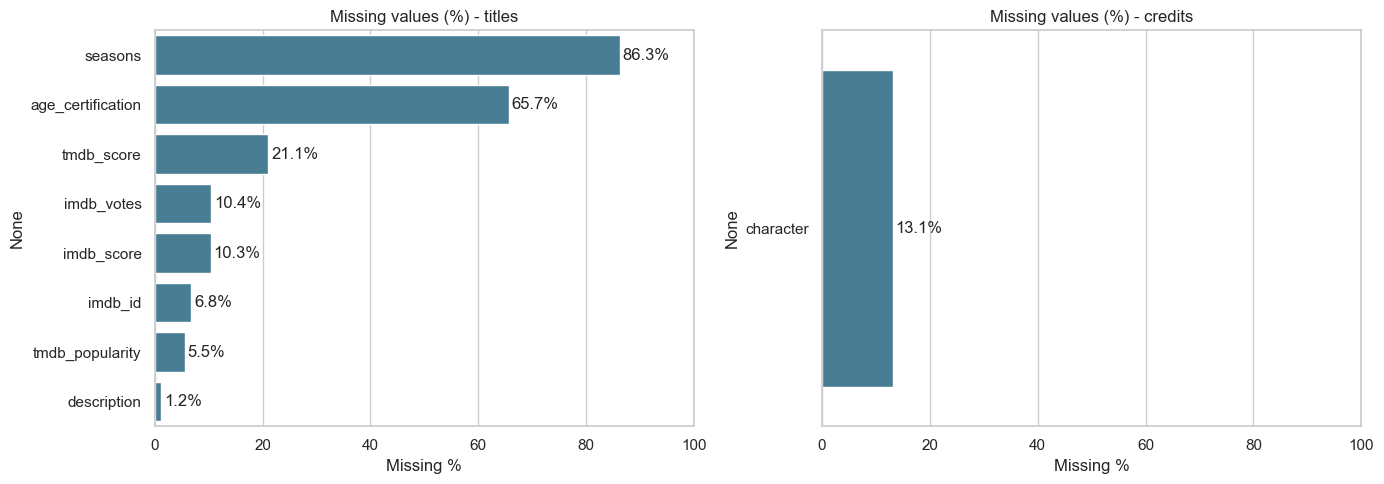

In [9]:
# Visualizing the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, d) in zip(axes, [("titles", titles), ("credits", credits)]):
    pct = (d.isna().mean() * 100).sort_values(ascending=False)
    pct = pct[pct > 0]
    sns.barplot(x=pct.values, y=pct.index, ax=ax, color="#3b82a0")
    ax.set_title(f"Missing values (%) - {name}")
    ax.set_xlabel("Missing %")
    for i, v in enumerate(pct.values):
        ax.text(v + 0.5, i, f"{v:.1f}%", va="center")
    ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

### What did you know about your dataset?

**Dataset overview**
- `titles` has **9,871 rows × 15 columns** (**9,868 unique `id`s**). `credits` has **124,235 rows × 5 columns** across **8,861 unique titles**.
- Content mix: **8,514 movies** and **1,357 TV shows**. Release years run from 1912 to 2022 (median 2014).
- Credits contain 115,846 ACTOR and 8,389 DIRECTOR records.

**Relationship between the files**
- `id` is the common key. Every `id` in `credits` exists in `titles` (0 orphans), but **1,007 titles have no credits**.
- A title has many credit rows (median 11, max 137), so the relationship is **one-to-many**. Credits must be aggregated to one row per title before merging to avoid row multiplication.

**Data quality issues found**
- Duplicates: 3 duplicated title records (`id` not unique) and 56 exact duplicate rows in `credits`.
- Missing values (titles): `seasons` 8,514 (all movies, so structural), `age_certification` 6,487 (~65.7%), `tmdb_score` 2,082 (~21.1%), `imdb_votes` 1,031, `imdb_score` 1,021 (~10.3%), `imdb_id` 667, `tmdb_popularity` 547, `description` 119.
- Missing values (credits): `character` 16,287.
- `genres` and `production_countries` are stored as text that looks like a list, so they need parsing.
- `imdb_votes` and `tmdb_popularity` are heavily right-skewed (e.g. `imdb_votes` median 462.5 vs max 1,133,692), and `runtime` ranges from 1 to 549 minutes.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
print("titles columns :", list(titles.columns))
print("\ncredits columns:", list(credits.columns))

titles columns : ['id', 'title', 'type', 'description', 'release_year', 'age_certification', 'runtime', 'genres', 'production_countries', 'seasons', 'imdb_id', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']

credits columns: ['person_id', 'id', 'name', 'character', 'role']


In [11]:
# Dataset Describe
print("=== TITLES: numeric columns ===")
display(titles.describe().T.round(2))
print("\n=== TITLES: categorical/text columns ===")
display(titles.describe(include="object").T if titles.select_dtypes("object").shape[1] else titles.describe(exclude="number").T)
print("\n=== CREDITS ===")
display(credits.describe(include="all").T)

=== TITLES: numeric columns ===


,count,mean,std,min,25%,50%,75%,max
release_year,9871.0,2001.33,25.81,1912.0,1995.50,2014.00,2018.00,2022.00
runtime,9871.0,85.97,33.51,1.0,65.00,89.00,102.00,549.00
seasons,1357.0,2.79,4.15,1.0,1.00,1.00,3.00,51.00
imdb_score,8850.0,5.98,1.34,1.1,5.10,6.10,6.90,9.90
imdb_votes,8840.0,8533.61,45920.15,5.0,117.00,462.50,2236.25,1133692.00
tmdb_popularity,9324.0,6.91,30.00,0.0,1.23,2.54,5.63,1437.91
tmdb_score,7789.0,5.98,1.52,0.8,5.10,6.00,6.90,10.00



=== TITLES: categorical/text columns ===


,count,unique,top,freq
id,9871,9868,tm89134,2
title,9871,9737,The Lost World,3
type,9871,2,MOVIE,8514
description,9752,9734,No overview found.,5
age_certification,3384,11,R,1249
genres,9871,2028,['drama'],908
production_countries,9871,497,['US'],4810
imdb_id,9204,9201,tt0033683,2



=== CREDITS ===


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_id,124235.0,NaN,NaN,NaN,406473.683986,561629.646076,1.0,38992.0,133949.0,571256.0,2371153.0
id,124235,8861,tm458582,137,NaN,NaN,NaN,NaN,NaN,NaN,NaN
name,124235,79758,George 'Gabby' Hayes,49,NaN,NaN,NaN,NaN,NaN,NaN,NaN
character,107948,71097,Himself,1540,NaN,NaN,NaN,NaN,NaN,NaN,NaN
role,124235,2,ACTOR,115846,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description

**titles (9,871 rows × 15 columns)**

| Variable | Type | Description |
|---|---|---|
| id | Text | Title ID on JustWatch (merge key) |
| title | Text | Name of the title |
| type | Categorical | MOVIE or SHOW |
| description | Text | Brief description |
| release_year | Integer | Year of release |
| age_certification | Categorical | Age rating (e.g. R, TV-PG) |
| runtime | Integer | Length in minutes (episode length for shows, film length for movies) |
| genres | Text (list) | List of genres |
| production_countries | Text (list) | List of producing countries |
| seasons | Float | Number of seasons (only for shows) |
| imdb_id | Text | Title ID on IMDb |
| imdb_score | Float | IMDb rating |
| imdb_votes | Float | Number of IMDb votes |
| tmdb_popularity | Float | Popularity on TMDB |
| tmdb_score | Float | Score on TMDB |

**credits (124,235 rows × 5 columns)**

| Variable | Type | Description |
|---|---|---|
| person_id | Integer | Person ID on JustWatch |
| id | Text | Title ID on JustWatch (links to `titles.id`) |
| name | Text | Actor or director name |
| character | Text | Character name (missing for many directors and some actors) |
| role | Categorical | ACTOR or DIRECTOR |

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for name, d in [("titles", titles), ("credits", credits)]:
    print(f"\n=== {name} ===")
    uniq = d.nunique().sort_values(ascending=False)
    display(uniq.to_frame("unique_values"))

# Show the actual values for the small categorical columns
print("\ntitles.type values            :", titles["type"].unique().tolist())
print("titles.age_certification      :", titles["age_certification"].dropna().unique().tolist())
print("credits.role values           :", credits["role"].unique().tolist())


=== titles ===


,unique_values
id,9868
title,9737
description,9734
imdb_id,9201
tmdb_popularity,5325
imdb_votes,3650
genres,2028
production_countries,497
runtime,207
release_year,110



=== credits ===


,unique_values
person_id,80508
name,79758
character,71097
id,8861
role,2



titles.type values            : ['SHOW', 'MOVIE']
titles.age_certification      : ['TV-PG', 'PG', 'G', 'PG-13', 'R', 'TV-G', 'TV-Y', 'TV-14', 'NC-17', 'TV-Y7', 'TV-MA']
credits.role values           : ['ACTOR', 'DIRECTOR']


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# ---------- 1. CLEAN TITLES ----------
titles_c = titles.copy()

# 1a. Remove exact duplicate rows, then guarantee one row per id
before = len(titles_c)
titles_c = titles_c.drop_duplicates()
titles_c["_nn"] = titles_c.notna().sum(axis=1)                 # keep the most complete record per id
titles_c = (titles_c.sort_values("_nn", ascending=False)
                    .drop_duplicates("id").drop(columns="_nn")
                    .sort_index().reset_index(drop=True))
print(f"titles: {before} -> {len(titles_c)} rows | id unique: {titles_c['id'].is_unique}")

# 1b. Missing values (decision per column)
titles_c["seasons"] = titles_c["seasons"].fillna(0)                        # NaN = movie (structural), 0 seasons
titles_c["age_certification"] = titles_c["age_certification"].fillna("Unrated")
titles_c["description"] = titles_c["description"].fillna("No description")
# imdb_score / imdb_votes / tmdb_* are NOT imputed (imputing a rating would invent data);
# rows with missing target are dropped only at modelling time.

# 1c. Parse list-like text columns safely
def parse_list(x):
    try:
        v = ast.literal_eval(x)
        return v if isinstance(v, list) else []
    except Exception:
        return []

titles_c["genre_list"] = titles_c["genres"].apply(parse_list)
titles_c["country_list"] = titles_c["production_countries"].apply(parse_list)
titles_c["n_genres"] = titles_c["genre_list"].str.len()
titles_c["n_countries"] = titles_c["country_list"].str.len()
titles_c["primary_genre"] = titles_c["genre_list"].apply(lambda l: l[0] if l else "unknown")
titles_c["primary_country"] = titles_c["country_list"].apply(lambda l: l[0] if l else "unknown")

# 1d. Derived time features
titles_c["decade"] = (titles_c["release_year"] // 10 * 10).astype(int)

# 1e. Outlier FLAGS (kept in data for EDA; handled later for ML)
def iqr_flag(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i)
for col in ["runtime", "imdb_votes", "tmdb_popularity"]:
    titles_c[f"{col}_outlier"] = iqr_flag(titles_c[col])
    print(f"{col}: {titles_c[f'{col}_outlier'].sum()} IQR outliers")

# ---------- 2. CLEAN CREDITS ----------
credits_c = credits.copy()
before = len(credits_c)
credits_c = credits_c.drop_duplicates(subset=["id", "person_id", "role"]).reset_index(drop=True)
credits_c["character"] = credits_c["character"].fillna("Unknown")
credits_c["name"] = credits_c["name"].str.strip()
print(f"credits: {before} -> {len(credits_c)} rows (duplicates on id+person+role removed)")

# ---------- 3. AGGREGATE CREDITS TO ONE ROW PER TITLE ----------
actors = (credits_c[credits_c["role"] == "ACTOR"].groupby("id")
          .agg(n_actors=("person_id", "nunique"),
               top_cast=("name", lambda s: ", ".join(s.head(3)))))
directors = (credits_c[credits_c["role"] == "DIRECTOR"].groupby("id")
             .agg(n_directors=("person_id", "nunique"), director=("name", "first")))
credit_agg = actors.join(directors, how="outer").reset_index()

# ---------- 4. MERGE (validate stops the code if rows would multiply) ----------
df = titles_c.merge(credit_agg, on="id", how="left", validate="one_to_one")
df[["n_actors", "n_directors"]] = df[["n_actors", "n_directors"]].fillna(0).astype(int)
df["top_cast"] = df["top_cast"].fillna("Unknown")
df["director"] = df["director"].fillna("Unknown")
df["has_credits"] = df["id"].isin(credits_c["id"])

# ---------- 5. SANITY CHECKS ----------
assert len(df) == len(titles_c), "Row count changed after merge!"
assert df["id"].is_unique
assert credits_c["id"].isin(titles_c["id"]).all()
print(f"\nMERGED df shape: {df.shape} | titles without credits: {(~df['has_credits']).sum()}")
print("n_actors + n_directors total:", df["n_actors"].sum(), "+", df["n_directors"].sum(),
      "| credits_c rows:", len(credits_c))

df.to_csv("amazon_prime_merged.csv", index=False)
credits_c.to_csv("credits_clean.csv", index=False)
print("Saved: amazon_prime_merged.csv, credits_clean.csv")
df.head(3)

titles: 9871 -> 9868 rows | id unique: True
runtime: 275 IQR outliers
imdb_votes: 1354 IQR outliers
tmdb_popularity: 916 IQR outliers
credits: 124235 -> 124003 rows (duplicates on id+person+role removed)

MERGED df shape: (9868, 30) | titles without credits: 1007
n_actors + n_directors total: 115617 + 8386 | credits_c rows: 124003
Saved: amazon_prime_merged.csv, credits_clean.csv


,id,title,type,description,release_year,age_certification,runtime,genres,production_countries,seasons,imdb_id,imdb_score,imdb_votes,tmdb_popularity,tmdb_score,genre_list,country_list,n_genres,n_countries,primary_genre,primary_country,decade,runtime_outlier,imdb_votes_outlier,tmdb_popularity_outlier,n_actors,top_cast,n_directors,director,has_credits
0,ts20945,The Three Stooges,SHOW,The Three Stooges were an American vaudeville ...,1934,TV-PG,19,"['comedy', 'family', 'animation', 'action', 'f...",['US'],26.0,tt0850645,8.6,1092.0,15.424,7.6,"[comedy, family, animation, action, fantasy, h...",[US],6,1,comedy,US,1930,False,False,True,3,"Joe Besser, Moe Howard, Larry Fine",0,Unknown,True
1,tm19248,The General,MOVIE,"During America’s Civil War, Union spies steal ...",1926,Unrated,78,"['action', 'drama', 'war', 'western', 'comedy'...",['US'],0.0,tt0017925,8.2,89766.0,8.647,8.0,"[action, drama, war, western, comedy, european]",[US],6,1,action,US,1920,False,True,False,22,"Buster Keaton, Marion Mack, Glen Cavender",2,Clyde Bruckman,True
2,tm82253,The Best Years of Our Lives,MOVIE,It's the hope that sustains the spirit of ever...,1946,Unrated,171,"['romance', 'war', 'drama']",['US'],0.0,tt0036868,8.1,63026.0,8.435,7.8,"[romance, war, drama]",[US],3,1,romance,US,1940,True,True,False,30,"Myrna Loy, Fredric March, Dana Andrews",1,William Wyler,True


### What all manipulations have you done and insights you found?

In [14]:
print(df.isna().sum()[df.isna().sum() > 0], "\n")
print("runtime<5:", (df["runtime"] < 5).sum(), "| runtime>240:", (df["runtime"] > 240).sum())
print(df["type"].value_counts(), "\n")
print(df["age_certification"].value_counts(), "\n")
print("empty genres:", (df["n_genres"] == 0).sum(), "| empty countries:", (df["n_countries"] == 0).sum())
print("release_year range:", df["release_year"].min(), "-", df["release_year"].max())
print(df.groupby("type")[["runtime", "seasons", "imdb_score", "n_actors"]].mean().round(2))

imdb_id             667
imdb_score         1021
imdb_votes         1031
tmdb_popularity     547
tmdb_score         2080
dtype: int64 

runtime<5: 32 | runtime>240: 10
type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64 

age_certification
Unrated    6484
R          1249
PG-13       588
PG          582
G           269
TV-MA       217
TV-14       188
TV-PG        91
TV-Y         78
TV-G         57
TV-Y7        52
NC-17        13
Name: count, dtype: int64 

empty genres: 209 | empty countries: 821
release_year range: 1912 - 2022
       runtime  seasons  imdb_score  n_actors
type                                         
MOVIE    93.98     0.00        5.80     12.67
SHOW     35.80     2.79        7.12      5.72


**Manipulations performed**
1. **Duplicates:** Removed the 3 duplicated title records, leaving **9,868 titles with a unique `id`** (8,511 movies, 1,357 shows). Removed duplicate credit rows (same `id` + `person_id` + `role`).
2. **Missing values:**
   - `seasons` filled with 0 for movies (structural, not truly missing).
   - `age_certification` filled with "Unrated" (6,484 titles).
   - `description` filled with "No description".
   - `imdb_score` (1,021), `imdb_votes` (1,031), `tmdb_score` (2,080), `tmdb_popularity` (547) and `imdb_id` (667) were **deliberately not imputed**, because filling in ratings would invent data. They are excluded only where a specific analysis needs them.
   - `character` in credits filled with "Unknown".
3. **Parsing:** Converted the text-lists in `genres` and `production_countries` into real lists, then derived `primary_genre`, `primary_country`, `n_genres` and `n_countries`. 209 titles have no genre and 821 have no country; they are labelled "unknown" rather than dropped.
4. **Merge:** `credits` is one-to-many against `titles`, so it was aggregated to one row per title (`n_actors`, `n_directors`, `top_cast`, `director`) and left-joined onto `titles` with a one-to-one check. Row count stayed at 9,868. Titles with no credits get 0 counts and `director = Unknown`.
5. **New features:** `decade`, `has_credits`, and IQR outlier flags for `runtime`, `imdb_votes` and `tmdb_popularity`. Outliers are flagged, not removed, because extreme values (e.g. blockbuster vote counts) are real.

**Early insights**
- The catalogue is dominated by movies (8,511 vs 1,357 shows).
- Most titles (6,484) carry no age certification, so certification analysis covers only about a third of the catalogue.
- Shows average about 36 minutes per episode against about 94 for movies. 32 titles have a runtime under 5 minutes and 10 exceed 240 minutes, so runtime outliers are handled with care.
- Among titles with a rating, shows average an IMDb score of 7.12 against 5.80 for movies.
- Movies average 12.67 listed actors per title against 5.72 for shows. This average includes titles with no credits (counted as 0).

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

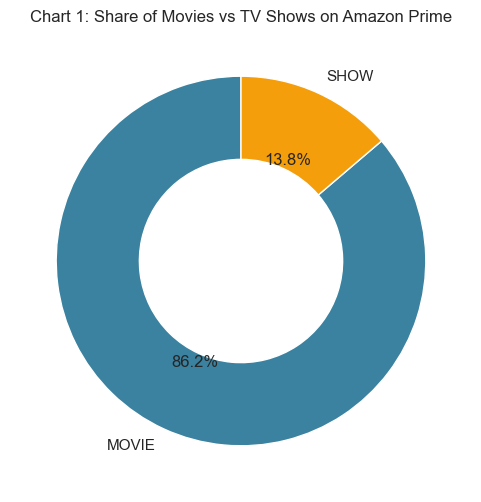

type
MOVIE    8511
SHOW     1357
Name: count, dtype: int64
type
MOVIE    86.25
SHOW     13.75
Name: count, dtype: float64


In [15]:
# Chart - 1 visualization code: Movies vs TV Shows (donut chart)
type_counts = df["type"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
        colors=["#3b82a0", "#f59e0b"], wedgeprops={"width": 0.45, "edgecolor": "white"})
plt.title("Chart 1: Share of Movies vs TV Shows on Amazon Prime")
plt.show()

# Numbers behind the chart
print(type_counts)
print((type_counts / len(df) * 100).round(2))

##### 1. Why did you pick the specific chart?

A donut chart is the clearest way to show how a whole catalogue splits into two parts (Movies vs TV Shows) as percentages.

##### 2. What is/are the insight(s) found from the chart?

Movies make up **86.2% (8,511)** of the 9,868 titles, while TV shows are only **13.8% (1,357)**. The platform is overwhelmingly movie-driven.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** A large movie library suits one-off viewing and gives breadth. Since shows are scarce, adding series is a clear opportunity, because series encourage repeat viewing and longer subscriptions.
**Negative:** The thin TV-show catalogue (13.8%) may leave binge-watching audiences underserved and could hurt retention against series-heavy competitors.

#### Chart - 2

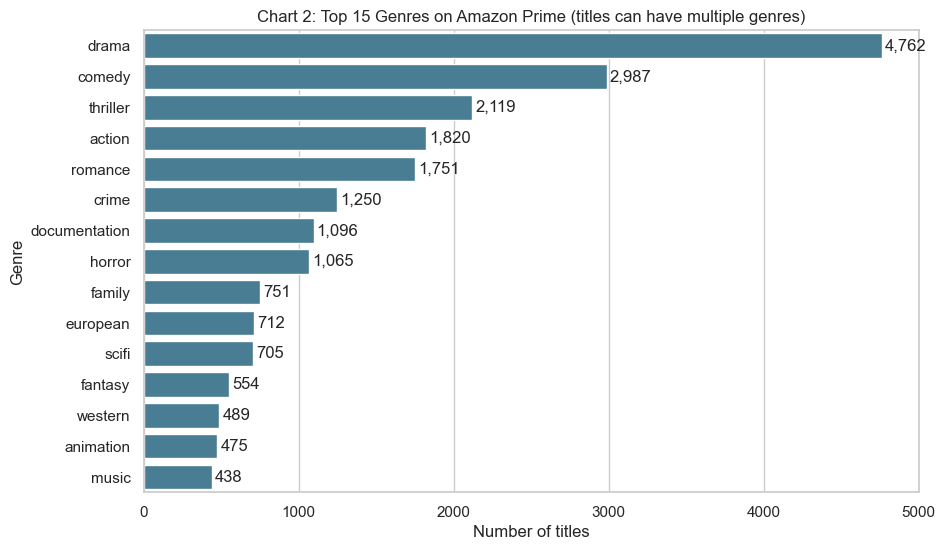

Unique genres: 19
Average genres per title: 2.24
genre_list
drama            4762
comedy           2987
thriller         2119
action           1820
romance          1751
crime            1250
documentation    1096
horror           1065
family            751
european          712
scifi             705
fantasy           554
western           489
animation         475
music             438
Name: count, dtype: int64


In [16]:
# Chart - 2 visualization code: Top 15 genres (a title can have several genres)
genre_counts = df["genre_list"].explode().value_counts()
top_genres = genre_counts.head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index, color="#3b82a0")
plt.title("Chart 2: Top 15 Genres on Amazon Prime (titles can have multiple genres)")
plt.xlabel("Number of titles")
plt.ylabel("Genre")
for i, v in enumerate(top_genres.values):
    plt.text(v + 20, i, f"{v:,}", va="center")
plt.show()

# Numbers behind the chart
print("Unique genres:", genre_counts.shape[0])
print("Average genres per title:", round(df["n_genres"].mean(), 2))
print(top_genres)

##### 1. Why did you pick the specific chart?

A horizontal bar chart ranks categories with long names easily. Titles can carry several genres, so counting each genre mention shows the genre mix.

##### 2. What is/are the insight(s) found from the chart?

There are **19 unique genres**, and a title carries **2.24 genres on average**. **Drama (4,762), comedy (2,987) and thriller (2,119)** lead, followed by action (1,820) and romance (1,751). Family (751), animation (475) and music (438) sit at the low end of the top 15.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** The catalogue is dominated by mainstream genres, which helps broad appeal. Documentation (1,096) and horror (1,065) are sizeable niches that can serve dedicated audiences.
**Negative:** Family and animation have comparatively few titles, so households with children are served less well. This could limit subscriptions from family accounts.

#### Chart - 3

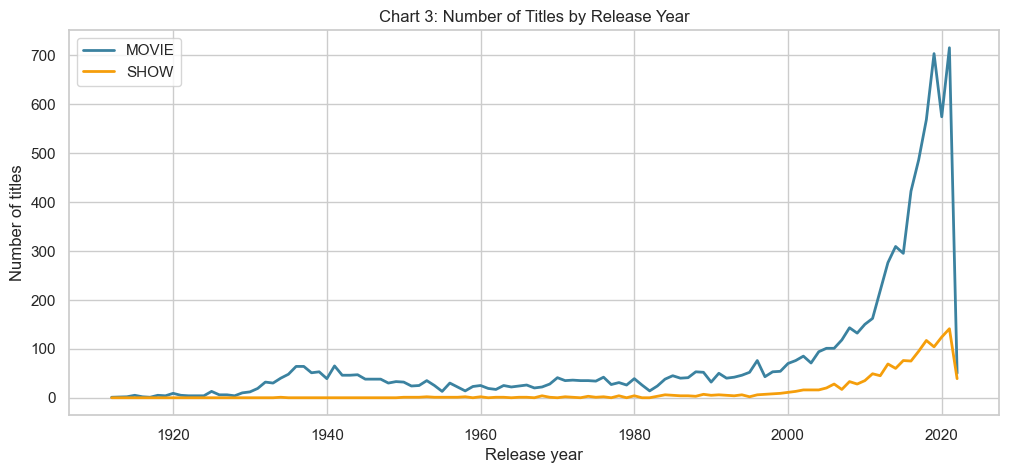

Peak year: 2021 -> 856 titles
Share released since 2000: 72.4%
Share released since 2010: 60.4%
Share released before 1980: 17.9%

Last 8 years:
type          MOVIE  SHOW
release_year             
2015            295    76
2016            422    75
2017            486    95
2018            568   117
2019            703   104
2020            574   124
2021            715   141
2022             50    39


In [17]:
# Chart - 3 visualization code: Titles released per year, by type (trend over time)
yearly = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)

plt.figure(figsize=(12, 5))
for col, color in zip(yearly.columns, ["#3b82a0", "#f59e0b"]):
    plt.plot(yearly.index, yearly[col], label=col, color=color, linewidth=2)
plt.title("Chart 3: Number of Titles by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

# Numbers behind the chart
total_by_year = yearly.sum(axis=1)
print("Peak year:", total_by_year.idxmax(), "->", total_by_year.max(), "titles")
print("Share released since 2000: %.1f%%" % (df["release_year"].ge(2000).mean() * 100))
print("Share released since 2010: %.1f%%" % (df["release_year"].ge(2010).mean() * 100))
print("Share released before 1980: %.1f%%" % (df["release_year"].lt(1980).mean() * 100))
print("\nLast 8 years:")
print(yearly.tail(8))

##### 1. Why did you pick the specific chart?

A line chart is the standard choice for a trend over time, and splitting it by type shows whether movies and shows grew differently.

##### 2. What is/are the insight(s) found from the chart?

Output is low and flat for decades, then climbs sharply after 2000. **72.4%** of titles were released since 2000, **60.4%** since 2010, and only **17.9%** before 1980. The peak is **2021 with 856 titles** (715 movies, 141 shows). Movies per year rose from 295 in 2015 to 715 in 2021, and shows from 76 to 141. 2020 dips for movies (574 from 703 in 2019). The apparent fall in 2022 (89 titles) most likely reflects a partial year of data, so it should not be read as a real decline.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** The library is recent-heavy and growing, which suits audiences who want current content. Shows are growing steadily in absolute terms.
**Negative:** Only 17.9% of titles are pre-1980, so classic and catalogue depth is limited. The 2022 drop is a data-coverage caveat, so it should not drive strategy.

#### Chart - 4

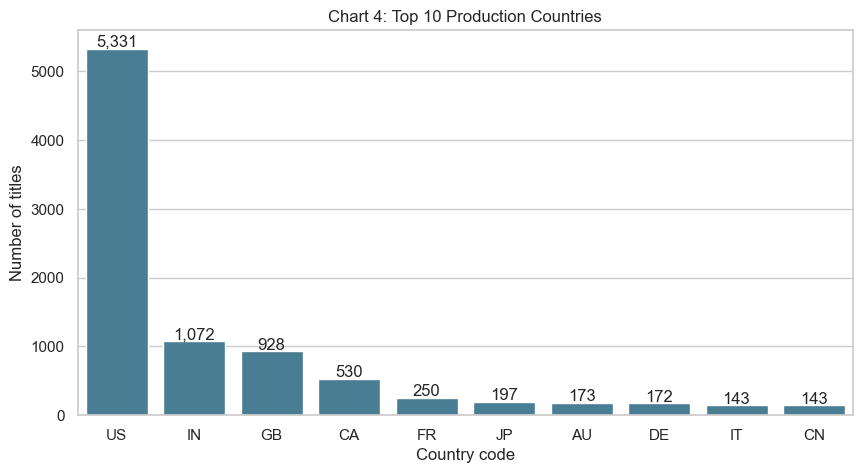

Titles with a country listed: 9047 | without: 821
Unique countries: 117
country_list
US    5331
IN    1072
GB     928
CA     530
FR     250
JP     197
AU     173
DE     172
IT     143
CN     143
Name: count, dtype: int64
US share of titles with a country: 58.9%
Top-5 countries' combined mentions share: 79.1%


In [18]:
# Chart - 4 visualization code: Top 10 production countries (titles can have several countries)
country_counts = df["country_list"].explode().value_counts()
top_countries = country_counts.head(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_countries.index, y=top_countries.values, color="#3b82a0")
plt.title("Chart 4: Top 10 Production Countries")
plt.xlabel("Country code")
plt.ylabel("Number of titles")
for i, v in enumerate(top_countries.values):
    plt.text(i, v + 30, f"{v:,}", ha="center")
plt.show()

# Numbers behind the chart
with_country = (df["n_countries"] > 0).sum()
print("Titles with a country listed:", with_country, "| without:", (df["n_countries"] == 0).sum())
print("Unique countries:", country_counts.shape[0])
print(top_countries)
print("US share of titles with a country: %.1f%%" % (df["country_list"].apply(lambda l: "US" in l).sum() / with_country * 100))
print("Top-5 countries' combined mentions share: %.1f%%" % (country_counts.head(5).sum() / country_counts.sum() * 100))

##### 1. Why did you pick the specific chart?

A bar chart ranks countries by title count, and showing only the top 10 keeps 117 countries readable.

##### 2. What is/are the insight(s) found from the chart?

The **US dominates with 5,331 titles (58.9%** of the 9,047 titles with a country listed). It is followed by **India (1,072), Great Britain (928), Canada (530) and France (250)**. The top 5 account for **79.1%** of all country mentions across 117 countries. 821 titles have no country listed.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** India is a clear second, which supports regional-language content strategy for a large market. Existing UK and Canadian content supports English-language international reach.
**Negative:** Heavy US dependence and thin presence from Japan (197), Germany (172), Italy (143) and China (143) mean limited regional diversity, which may hold back growth in non-English markets.

#### Chart - 5

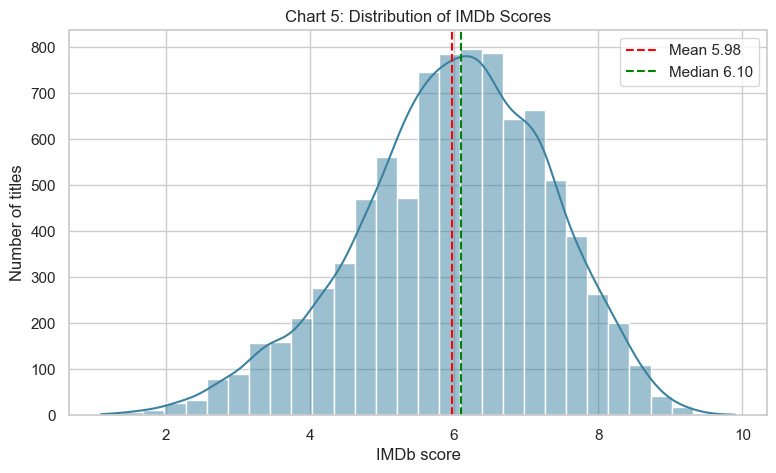

Titles with a score: 8847
Mean: 5.98 | Median: 6.10 | Std: 1.34
Share >= 8.0: 6.1% | Share < 5.0: 21.0%


In [19]:
# Chart - 5 visualization code: Distribution of IMDb scores
scores = df["imdb_score"].dropna()

plt.figure(figsize=(9, 5))
sns.histplot(scores, bins=30, kde=True, color="#3b82a0")
plt.axvline(scores.mean(), color="red", linestyle="--", label=f"Mean {scores.mean():.2f}")
plt.axvline(scores.median(), color="green", linestyle="--", label=f"Median {scores.median():.2f}")
plt.title("Chart 5: Distribution of IMDb Scores")
plt.xlabel("IMDb score")
plt.ylabel("Number of titles")
plt.legend()
plt.show()

# Numbers behind the chart
print("Titles with a score:", len(scores))
print("Mean: %.2f | Median: %.2f | Std: %.2f" % (scores.mean(), scores.median(), scores.std()))
print("Share >= 8.0: %.1f%% | Share < 5.0: %.1f%%" % ((scores >= 8).mean() * 100, (scores < 5).mean() * 100))

##### 1. Why did you pick the specific chart?

A histogram with a density curve shows how ratings are spread, where most titles sit, and whether the distribution is skewed. Mean and median lines make the centre explicit.

##### 2. What is/are the insight(s) found from the chart?

Of the 9,868 titles, **8,847 have an IMDb score**. Scores average **5.98** (median **6.10**, std 1.34), so the distribution leans slightly towards higher values with a tail of low scores. Only **6.1%** of titles score 8.0 or above, while **21.0%** score below 5.0. Most of the catalogue is mid-rated.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** The small share of highly rated titles (6.1%) can be used for "critically acclaimed" collections and marketing, and ranking by score helps surface the best content.
**Negative:** One in five rated titles scores below 5.0, which can weaken perceived quality. Low-rated content should be reviewed for retention, renewal or curation. The score is also missing for 1,021 titles, so about 10% of the catalogue cannot be assessed.

#### Chart - 6

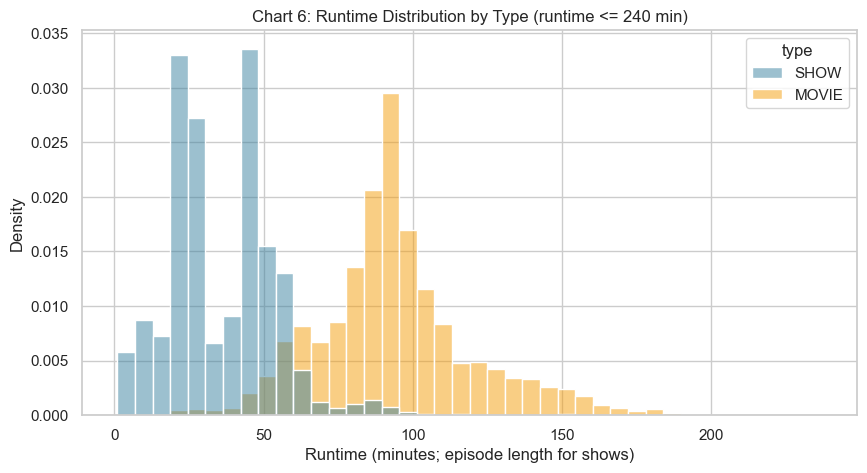

        count  mean   50%  min    max
type                                 
MOVIE  8511.0  94.0  91.0  1.0  549.0
SHOW   1357.0  35.8  33.0  1.0  153.0
Titles above 240 min (not plotted): 10
Movies with runtime < 60 min: 8.9%


In [21]:
# Chart - 6 visualization code: Runtime distribution by type (clipped at 240 min for readability only)
plot_df = df[df["runtime"] <= 240]

plt.figure(figsize=(10, 5))
sns.histplot(data=plot_df, x="runtime", hue="type", bins=40, stat="density",
             common_norm=False, palette=["#3b82a0", "#f59e0b"])
plt.title("Chart 6: Runtime Distribution by Type (runtime <= 240 min)")
plt.xlabel("Runtime (minutes; episode length for shows)")
plt.ylabel("Density")
plt.show()

# Numbers behind the chart
print(df.groupby("type")["runtime"].describe()[["count", "mean", "50%", "min", "max"]].round(1))
print("Titles above 240 min (not plotted):", (df["runtime"] > 240).sum())
print("Movies with runtime < 60 min: %.1f%%" % ((df.loc[df['type'] == 'MOVIE', 'runtime'] < 60).mean() * 100))

##### 1. Why did you pick the specific chart?

Overlaid, normalised histograms compare the runtime shape of two groups of very different sizes (8,511 movies vs 1,357 shows). Normalising (density) keeps the smaller group visible.

##### 2. What is/are the insight(s) found from the chart?

Movies average **94.0 minutes** (median 91), while shows average **35.8 minutes per episode** (median 33). Movie runtimes reach 549 minutes and show episodes reach 153. **8.9%** of movies run under 60 minutes, and 10 titles exceed 240 minutes (not plotted). Runtime for shows means episode length, so the two types should not be compared as like for like.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Typical lengths (about 90 minutes for movies, about 30 minutes for episodes) are clear benchmarks for content acquisition and scheduling, and short-form titles can serve quick-viewing audiences.
**Negative:** Very short movies (under 60 minutes, 8.9%) and extreme runtimes may be shorts or data entries that blur the catalogue. They could mislead recommendations if not treated separately.

#### Chart - 7

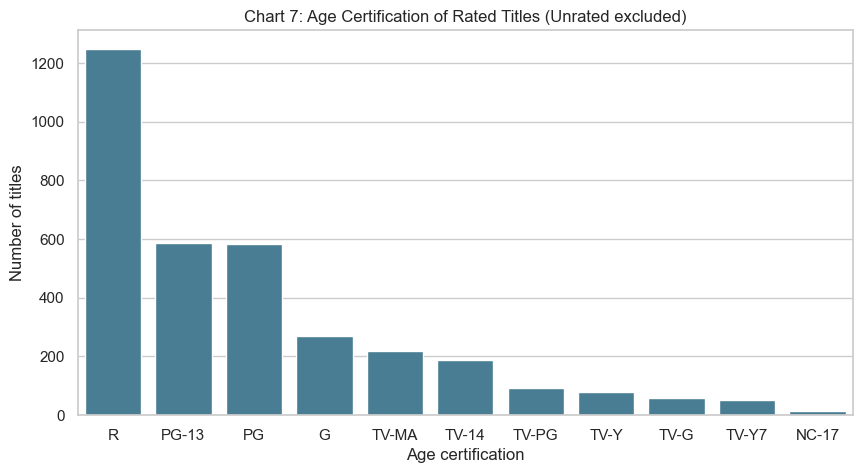

Rated titles: 3384 | Unrated: 6484
age_certification
R        1249
PG-13     588
PG        582
G         269
TV-MA     217
TV-14     188
TV-PG      91
TV-Y       78
TV-G       57
TV-Y7      52
NC-17      13
Name: count, dtype: int64
age_certification
R        36.9
PG-13    17.4
PG       17.2
G         7.9
TV-MA     6.4
TV-14     5.6
TV-PG     2.7
TV-Y      2.3
TV-G      1.7
TV-Y7     1.5
NC-17     0.4
Name: count, dtype: float64


In [22]:
# Chart - 7 visualization code: Age certifications (titles that have one)
rated = df[df["age_certification"] != "Unrated"]
order = rated["age_certification"].value_counts().index

plt.figure(figsize=(10, 5))
sns.countplot(data=rated, x="age_certification", order=order, color="#3b82a0")
plt.title("Chart 7: Age Certification of Rated Titles (Unrated excluded)")
plt.xlabel("Age certification")
plt.ylabel("Number of titles")
plt.show()

# Numbers behind the chart
vc = rated["age_certification"].value_counts()
print("Rated titles:", len(rated), "| Unrated:", (df["age_certification"] == "Unrated").sum())
print(vc)
print((vc / len(rated) * 100).round(1))

##### 1. Why did you pick the specific chart?

A count plot ranks the categories of a rating system. "Unrated" is excluded because it stands for a missing certification, not an official category.

##### 2. What is/are the insight(s) found from the chart?

Only **3,384 titles (34.3%) have an age certification**, and 6,484 do not, so this chart covers just the rated subset. **R leads at 36.9% (1,249)**, followed by **PG-13 (17.4%) and PG (17.2%)**. G is 7.9%. Among TV ratings, TV-MA is 6.4%, TV-14 is 5.6%, and the kid-oriented ratings TV-Y (2.3%), TV-G (1.7%) and TV-Y7 (1.5%) are small. NC-17 is the smallest at 0.4%.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Among rated titles, adult-oriented content is the largest block, which suits adult subscribers, and the broad PG/PG-13 base serves general audiences.
**Negative:** Children's TV content is thin among rated titles (TV-Y, TV-G and TV-Y7 together are only about 5.5%), and the two-thirds of titles with no certification make parental-control filtering unreliable. Filling in certifications would improve family targeting.

#### Chart - 8

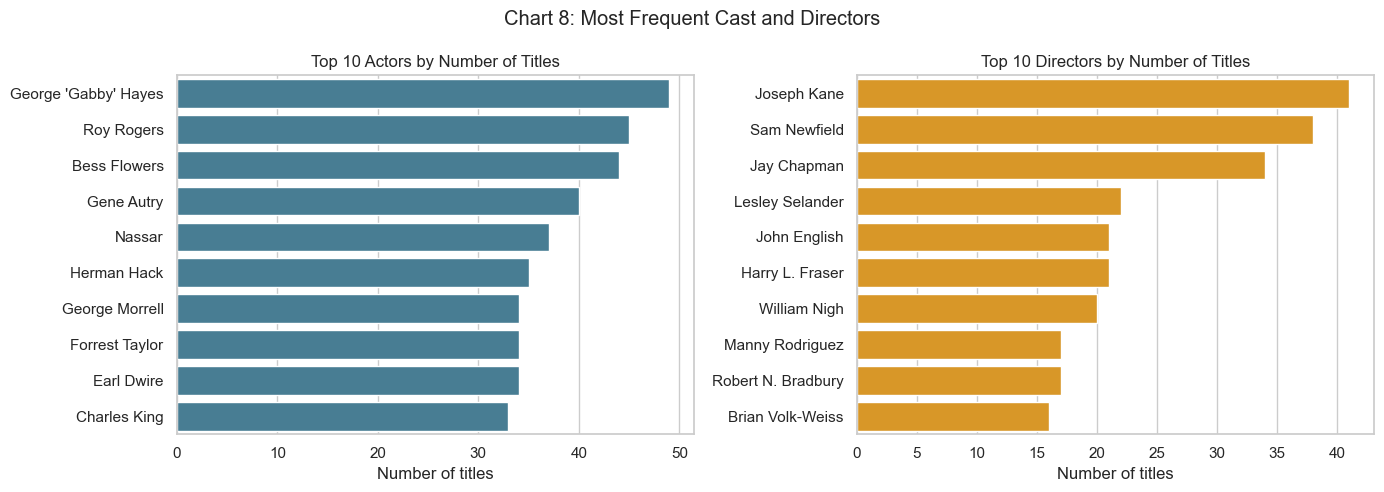

                name  titles
George 'Gabby' Hayes      49
          Roy Rogers      45
        Bess Flowers      44
          Gene Autry      40
              Nassar      37
         Herman Hack      35
      George Morrell      34
      Forrest Taylor      34
          Earl Dwire      34
        Charles King      33

              name  titles
       Joseph Kane      41
      Sam Newfield      38
       Jay Chapman      34
   Lesley Selander      22
      John English      21
   Harry L. Fraser      21
      William Nigh      20
   Manny Rodriguez      17
Robert N. Bradbury      17
  Brian Volk-Weiss      16


In [23]:
# Chart - 8 visualization code: Top 10 actors and directors by number of titles
def top_people(role):
    return (credits_c[credits_c["role"] == role]
            .groupby(["person_id", "name"]).size()
            .sort_values(ascending=False).head(10).reset_index(name="titles"))

actors_top, directors_top = top_people("ACTOR"), top_people("DIRECTOR")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=actors_top, x="titles", y="name", ax=axes[0], color="#3b82a0")
axes[0].set_title("Top 10 Actors by Number of Titles")
sns.barplot(data=directors_top, x="titles", y="name", ax=axes[1], color="#f59e0b")
axes[1].set_title("Top 10 Directors by Number of Titles")
for ax in axes:
    ax.set_ylabel("")
    ax.set_xlabel("Number of titles")
plt.suptitle("Chart 8: Most Frequent Cast and Directors")
plt.tight_layout()
plt.show()

# Numbers behind the chart
print(actors_top[["name", "titles"]].to_string(index=False))
print()
print(directors_top[["name", "titles"]].to_string(index=False))

##### 1. Why did you pick the specific chart?

Horizontal bar charts rank people with long names legibly. Using the long credits table (one row per credit) avoids counting a person once per merged row.

##### 2. What is/are the insight(s) found from the chart?

The most frequent actors appear in at most **49 titles** (George 'Gabby' Hayes 49, Roy Rogers 45, Bess Flowers 44, Gene Autry 40, Nassar 37). The most frequent directors are **Joseph Kane (41), Sam Newfield (38) and Jay Chapman (34)**, and only 5 directors exceed 20 titles. No individual appears in more than 49 of 9,868 titles, so talent is highly fragmented. Many of the names are not contemporary stars.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Recurring names can anchor "collections by actor or director", which helps discovery and search.
**Negative:** With no dominant modern names, the catalogue lacks star-power marketing hooks, and the most prolific people have few titles each. Prolific names are not a sign of audience appeal on their own.

#### Chart - 9

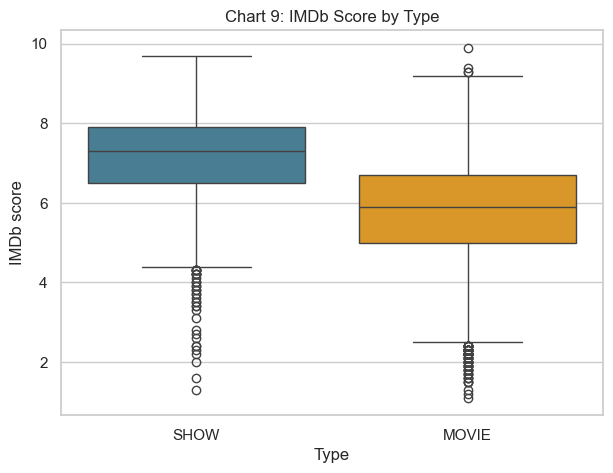

        count  mean  25%  50%  75%  min  max
type                                        
MOVIE  7681.0  5.80  5.0  5.9  6.7  1.1  9.9
SHOW   1166.0  7.12  6.5  7.3  7.9  1.3  9.7


In [24]:
# Chart - 9 visualization code: IMDb score by type (box plot)
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="type", y="imdb_score", palette=["#3b82a0", "#f59e0b"])
plt.title("Chart 9: IMDb Score by Type")
plt.xlabel("Type")
plt.ylabel("IMDb score")
plt.show()

# Numbers behind the chart
print(df.groupby("type")["imdb_score"].describe()[["count", "mean", "25%", "50%", "75%", "min", "max"]].round(2))

##### 1. Why did you pick the specific chart?

A box plot compares the median, spread (IQR) and outliers of a numeric variable across categories. It suits comparing IMDb score between Movies and TV Shows, which have very different group sizes.

##### 2. What is/are the insight(s) found from the chart?

TV shows are rated clearly higher than movies. Shows have a median of **7.3** (mean 7.12, IQR 6.5 to 7.9), while movies have a median of **5.9** (mean 5.80, IQR 5.0 to 6.7). The scored sample is 7,681 movies and 1,166 shows. Movies span a wider range (1.1 to 9.9) and include many low-scoring outliers. The gap is about 1.4 points in median, so a typical show is rated higher than three-quarters of movies. This is an association only, because shows and movies are rated by different audiences.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Shows are consistently better rated, which strengthens the case for expanding the series catalogue (only 13.8% of titles). High-rated shows can anchor retention and marketing.
**Negative:** Movies are 86% of the catalogue but have a median of only 5.9, so most viewing choices are mid-rated. 685 movies and 191 shows have no score, which limits this comparison. Higher show scores may partly reflect which shows get rated, not quality alone.

#### Chart - 10

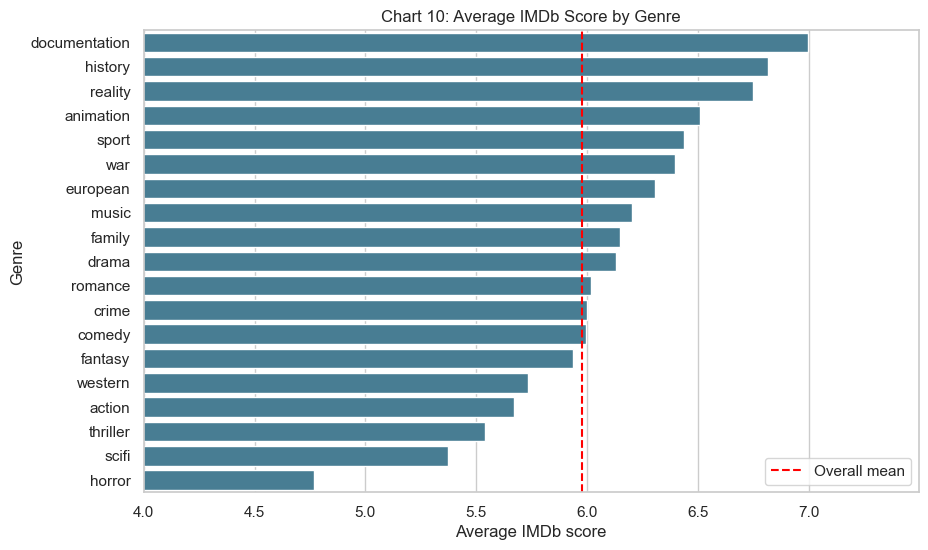

               mean  count
genre_list                
documentation  6.99    949
history        6.81    379
reality        6.75    129
animation      6.51    434
sport          6.44    224
war            6.40    316
european       6.31    698
music          6.20    395
family         6.15    724
drama          6.13   4487
romance        6.02   1717
crime          6.00   1212
comedy         5.99   2804
fantasy        5.94    535
western        5.73    480
action         5.67   1771
thriller       5.54   2010
scifi          5.37    673
horror         4.77   1001


In [25]:
# Chart - 10 visualization code: Average IMDb score by genre (genres with at least 100 scored titles)
g = df[["genre_list", "imdb_score"]].explode("genre_list").dropna(subset=["imdb_score"])
stats = g.groupby("genre_list")["imdb_score"].agg(["mean", "count"])
stats = stats[stats["count"] >= 100].sort_values("mean", ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x=stats["mean"], y=stats.index, color="#3b82a0")
plt.axvline(df["imdb_score"].mean(), color="red", linestyle="--", label="Overall mean")
plt.title("Chart 10: Average IMDb Score by Genre")
plt.xlabel("Average IMDb score")
plt.ylabel("Genre")
plt.xlim(4, stats["mean"].max() + 0.5)
plt.legend()
plt.show()

# Numbers behind the chart
print(stats.round(2))

##### 1. Why did you pick the specific chart?

A sorted horizontal bar chart ranks genres by average IMDb score, and long genre names stay readable. The red line (overall mean) shows which genres sit above or below the catalogue average. Only genres with at least 100 scored titles are shown, so averages are reliable.

##### 2. What is/are the insight(s) found from the chart?

Documentation leads with an average of **6.99** (949 scored titles), followed by history (**6.81**) and reality (**6.75**, 129 titles). Animation (6.51), sport (6.44) and war (6.40) also sit above the overall mean of 5.98. The lowest are **horror (4.77, 1,001 titles)**, sci-fi (5.37), thriller (5.54) and action (5.67). Drama, the largest genre, averages 6.13. Genres are not exclusive, so a title with several genres counts in each.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Documentary, history and reality content is both well rated and sizeable, so it can drive quality perception and "critically acclaimed" collections.
**Negative:** High-volume genres such as thriller (2,010 scored titles), action (1,771) and horror (1,001) rate below average, so a large share of the library is lower quality. Acquiring more of these without quality filtering risks weakening the platform's ratings. Differences between neighbouring genres are small and should not be over-read.

#### Chart - 11

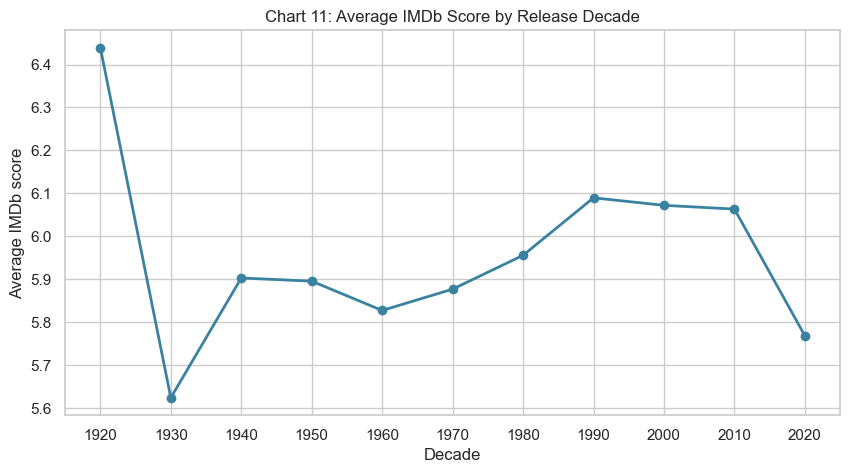

        mean  count
decade             
1920    6.44     64
1930    5.62    411
1940    5.90    410
1950    5.90    248
1960    5.83    234
1970    5.88    343
1980    5.96    378
1990    6.09    492
2000    6.07   1051
2010    6.06   3934
2020    5.77   1262


In [26]:
# Chart - 11 visualization code: Average IMDb score by release decade (decades with at least 30 scored titles)
dec = df.dropna(subset=["imdb_score"]).groupby("decade")["imdb_score"].agg(["mean", "count"])
dec = dec[dec["count"] >= 30]

plt.figure(figsize=(10, 5))
plt.plot(dec.index, dec["mean"], marker="o", color="#3b82a0", linewidth=2)
plt.title("Chart 11: Average IMDb Score by Release Decade")
plt.xlabel("Decade")
plt.ylabel("Average IMDb score")
plt.xticks(dec.index)
plt.show()

# Numbers behind the chart
print(dec.round(2))

##### 1. Why did you pick the specific chart?

A line chart with markers suits an ordered time variable, so it shows how the average IMDb score moves from decade to decade. Only decades with at least 30 scored titles are plotted, so small samples do not distort the trend.

##### 2. What is/are the insight(s) found from the chart?

Average scores stay in a narrow band across decades. The 1990s (**6.09**, 492 titles), 2000s (**6.07**, 1,051) and 2010s (**6.06**, 3,934) are almost identical, and older decades sit around 5.8 to 5.96. The 1930s are lowest at **5.62** (411 titles). The 1920s peak at 6.44 but rest on only 64 scored titles, so that point is unreliable. The 2020s fall to **5.77** (1,262 titles), the second-lowest decade. The data ends in 2022, so the 2020s are a partial decade. There is no clear long-term rise or fall in quality.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Older titles score about as well as recent ones (around 5.9 versus 6.06), so the back catalogue has real value and is worth promoting, for example through classic collections.
**Negative:** The 2020s average (5.77) is below the 2010s even though output has grown sharply, which suggests volume is rising faster than quality. This is a partial decade, so it should be monitored rather than treated as a firm trend.

#### Chart - 12

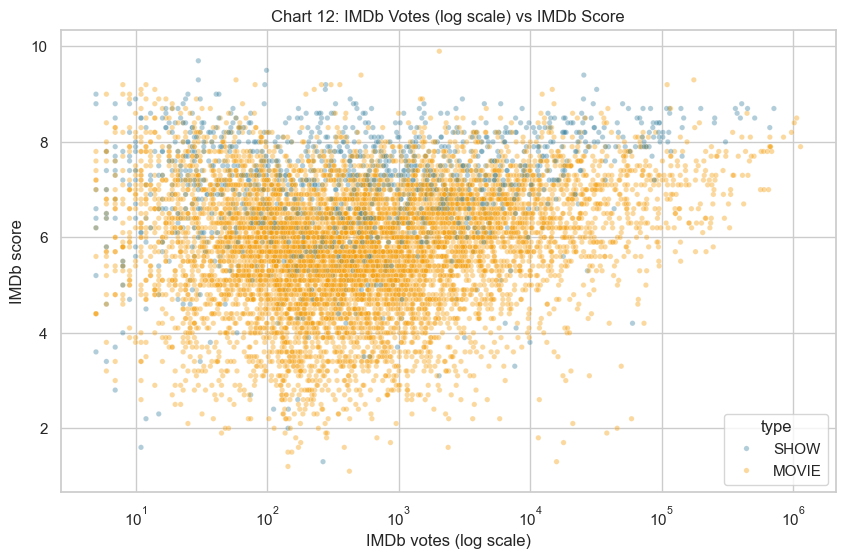

Titles used: 8837
Spearman correlation (score vs votes): 0.143
                   mean  count
imdb_votes                    
Q1 (fewest votes)  6.10   2230
Q2                 5.51   2191
Q3                 5.80   2207
Q4 (most votes)    6.50   2209


In [27]:
# Chart - 12 visualization code: IMDb votes (log scale) vs IMDb score
d = df.dropna(subset=["imdb_score", "imdb_votes"])

plt.figure(figsize=(10, 6))
sns.scatterplot(data=d, x="imdb_votes", y="imdb_score", hue="type", alpha=0.4, s=15,
                palette=["#3b82a0", "#f59e0b"])
plt.xscale("log")
plt.title("Chart 12: IMDb Votes (log scale) vs IMDb Score")
plt.xlabel("IMDb votes (log scale)")
plt.ylabel("IMDb score")
plt.show()

# Numbers behind the chart
print("Titles used:", len(d))
print("Spearman correlation (score vs votes): %.3f" % d["imdb_score"].corr(d["imdb_votes"], method="spearman"))
q = pd.qcut(d["imdb_votes"], 4, labels=["Q1 (fewest votes)", "Q2", "Q3", "Q4 (most votes)"])
print(d.groupby(q, observed=True)["imdb_score"].agg(["mean", "count"]).round(2))

##### 1. Why did you pick the specific chart?

A scatter plot shows the relationship between two numeric variables. IMDb votes are very skewed (1,354 IQR outliers), so a log scale spreads the points readably. Colouring by type shows whether movies and shows behave differently. Spearman correlation is used because it is robust to skew and outliers.

##### 2. What is/are the insight(s) found from the chart?

Across **8,837** titles with both a score and votes, the Spearman correlation is only **0.143**, a weak positive relationship. Grouping by vote quartile gives mean scores of **6.10** (fewest votes), **5.51**, **5.80** and **6.50** (most votes). The pattern is not steady: the lowest-voted group is not the lowest rated. The most-voted titles do score highest, about one point above Q2. Votes are only a loose signal of quality.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** The most-voted titles tend to be the best rated (6.50 mean), so votes combined with score can build more credible "popular and well rated" lists and recommendations.
**Negative:** A correlation of 0.143 means popularity alone is a poor guide to quality. Ranking by votes would promote mediocre popular titles and bury well-rated niche ones. Votes are also missing for about 1,031 titles, so those cannot be assessed.

#### Chart - 13

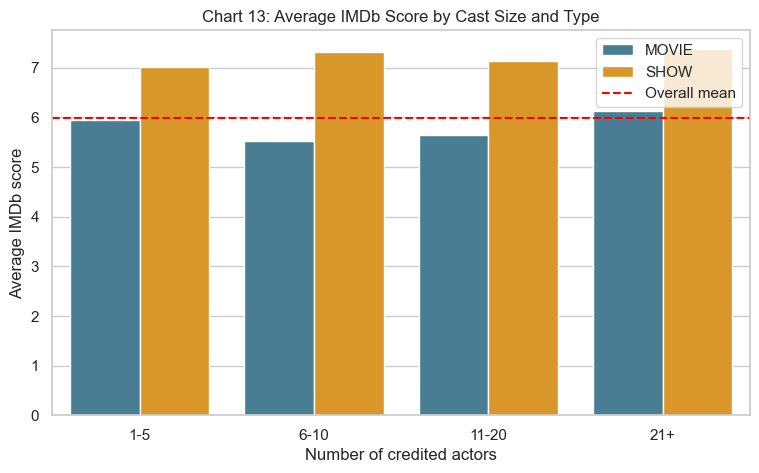

cast_size  type  mean  count
      1-5 MOVIE  5.95   1276
      1-5  SHOW  7.02    350
     6-10 MOVIE  5.52   1979
     6-10  SHOW  7.31    337
    11-20 MOVIE  5.64   2431
    11-20  SHOW  7.14    174
      21+ MOVIE  6.13   1377
      21+  SHOW  7.38     31
Spearman (n_actors vs imdb_score): -0.035


In [28]:
# Chart - 13 visualization code: Average IMDb score by cast size (titles with credits only)
# Titles without credits are excluded: their n_actors = 0 means "unknown", not "no cast".
d = df[(df["has_credits"]) & (df["n_actors"] > 0)].dropna(subset=["imdb_score"]).copy()
d["cast_size"] = pd.cut(d["n_actors"], bins=[0, 5, 10, 20, np.inf],
                        labels=["1-5", "6-10", "11-20", "21+"])

# Mean score and count per cast-size bucket and type (observed=True avoids empty groups)
g = (d.groupby(["cast_size", "type"], observed=True)["imdb_score"]
       .agg(["mean", "count"]).reset_index())

plt.figure(figsize=(9, 5))
sns.barplot(data=g, x="cast_size", y="mean", hue="type", palette=["#3b82a0", "#f59e0b"])
plt.axhline(df["imdb_score"].mean(), color="red", linestyle="--", label="Overall mean")
plt.title("Chart 13: Average IMDb Score by Cast Size and Type")
plt.xlabel("Number of credited actors")
plt.ylabel("Average IMDb score")
plt.legend()
plt.show()

# Numbers behind the chart
print(g.round(2).to_string(index=False))
print("Spearman (n_actors vs imdb_score): %.3f" % d["n_actors"].corr(d["imdb_score"], method="spearman"))

##### 1. Why did you pick the specific chart?

A grouped bar chart compares average IMDb score across cast-size buckets, split by type. The split is needed because shows and movies have very different cast sizes, and ignoring type would mix two populations. Only titles with credits are used, because a missing credit is not the same as zero actors.

##### 2. What is/are the insight(s) found from the chart?

TV shows score higher than movies in **every** cast-size bucket (**7.02 to 7.38** versus **5.52 to 6.13**). Within movies the pattern is uneven: 5.95 (1-5 actors), 5.52 (6-10), 5.64 (11-20) and 6.13 (21+). Overall, the Spearman correlation between cast size and IMDb score is **-0.035**, which is negligible. Cast size does not explain ratings, and type is the stronger factor. The 21+ show group has only 31 titles, so that bar is unreliable.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

**Positive:** Cast size is not a rating driver, so acquisition decisions should not be based on large ensemble casts. Type and genre matter more, which keeps the strategy simple.
**Negative:** There is no cast-size shortcut to higher quality, and the large-cast movie group (6.13) is only slightly above the overall mean of 5.98. Shows with big casts are too few (31) to draw conclusions, so more data would be needed.

#### Chart - 14 - Correlation Heatmap

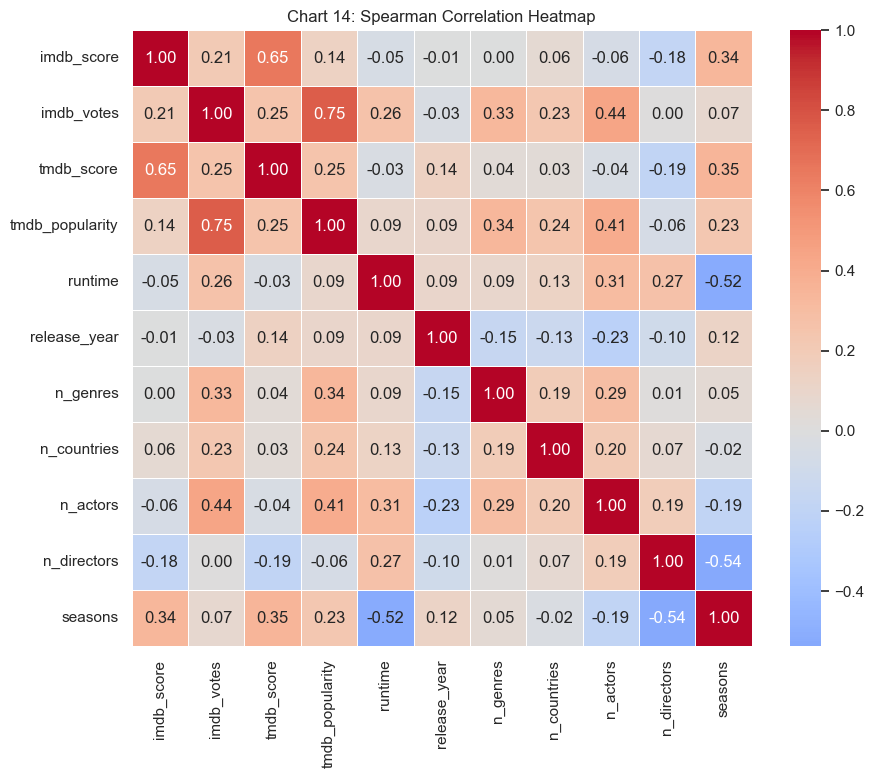

tmdb_score         0.647
seasons            0.336
imdb_votes         0.209
n_directors       -0.178
tmdb_popularity    0.136
n_countries        0.059
n_actors          -0.057
runtime           -0.046
release_year      -0.007
n_genres           0.001
Name: imdb_score, dtype: float64


In [29]:
# Correlation Heatmap visualization code
# Spearman is used because votes/popularity/runtime are skewed. Only titles with credits are used,
# so n_actors / n_directors are real counts and not structural zeros.
num_cols = ["imdb_score", "imdb_votes", "tmdb_score", "tmdb_popularity", "runtime",
            "release_year", "n_genres", "n_countries", "n_actors", "n_directors", "seasons"]
corr = df.loc[df["has_credits"], num_cols].corr(method="spearman")  # pairwise-complete, no imputation

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=0.5)
plt.title("Chart 14: Spearman Correlation Heatmap")
plt.show()

# Numbers behind the chart: strongest correlations with IMDb score
print(corr["imdb_score"].drop("imdb_score").sort_values(key=abs, ascending=False).round(3))

##### 1. Why did you pick the specific chart?

A correlation heatmap shows the strength and direction of relationships between all numeric variables at once. Spearman correlation is used because votes, popularity and runtime are skewed. Only titles with credits are included, so cast and director counts are real counts.

##### 2. What is/are the insight(s) found from the chart?

IMDb score correlates most with **tmdb_score (0.647)**, which is expected because both are audience ratings of the same titles. Next are **seasons (0.336)** and **imdb_votes (0.209)**. **n_directors (-0.178)** is mildly negative and may partly reflect the movie versus show split. tmdb_popularity (0.136), n_countries (0.059), n_actors (-0.057), runtime (-0.046), release_year (-0.007) and n_genres (0.001) show almost no relationship. These are associations, not causes. For ML, tmdb_score is another rating of the same title, so it should not be used to predict IMDb score, because that would leak the target.

#### Chart - 15 - Pair Plot

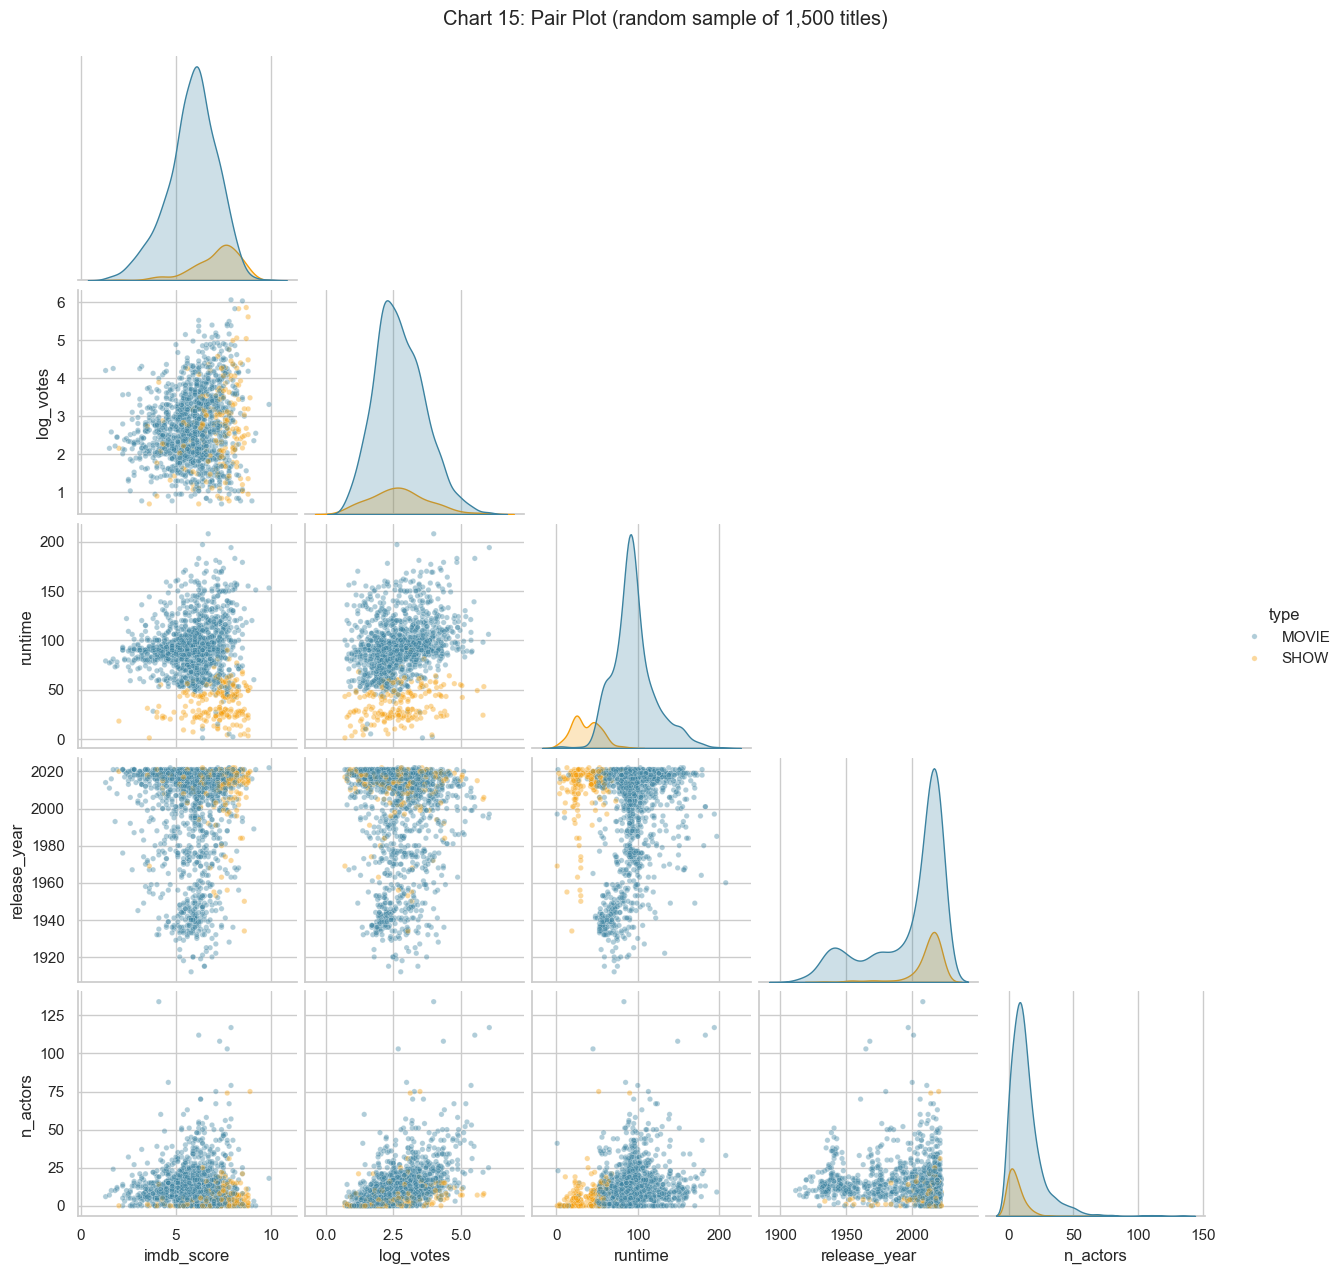

Rows plotted: 1500 | by type:
 type
MOVIE    1310
SHOW      190
Name: count, dtype: int64


In [30]:
# Pair Plot visualization code
# Work on a copy so df stays untouched for ML. Sample for speed and readability.
p = df.dropna(subset=["imdb_score", "imdb_votes"]).copy()
p = p[p["runtime"] <= 240]                      # clip extreme runtimes for readability only
p["log_votes"] = np.log10(p["imdb_votes"])      # votes are heavily skewed
p = p[["imdb_score", "log_votes", "runtime", "release_year", "n_actors", "type"]]
p = p.sample(n=min(1500, len(p)), random_state=42)

sns.pairplot(p, hue="type", palette={"MOVIE": "#3b82a0", "SHOW": "#f59e0b"},
             corner=True, plot_kws={"alpha": 0.4, "s": 15})
plt.suptitle("Chart 15: Pair Plot (random sample of 1,500 titles)", y=1.02)
plt.show()

print("Rows plotted:", len(p), "| by type:\n", p["type"].value_counts())

##### 1. Why did you pick the specific chart?

A pair plot shows every pairwise relationship among the key numeric variables in one grid, with distributions on the diagonal. It is the multivariate view of this analysis. Colouring by type shows how movies and shows differ. A random sample of 1,500 titles keeps it readable, and log-votes plus a runtime cut-off at 240 minutes are used for readability only.

##### 2. What is/are the insight(s) found from the chart?

The sample has **1,310 movies and 190 shows**, close to the catalogue mix. The grid reinforces earlier findings: shows and movies separate mainly on runtime (episode length versus film length) and score, and no single variable shows a strong straight-line link with IMDb score (see Charts 12 and 14). The most useful signal remains title type. (Check the panels once and add any pattern you see that the numbers above do not already cover.)

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?

**Recommendations for the client**
1. **Expand TV series.** Shows are only 13.8% of the catalogue yet have a median IMDb score of 7.3 against 5.9 for movies, and seasons correlate positively with score (0.336).
2. **Invest in strong, under-served genres.** Documentary (6.99), history (6.81) and reality (6.75) rate highest. Family (751) and animation (475) are thin, so adding them would serve households with children.
3. **Curate the weak, high-volume genres.** Horror (4.77), sci-fi (5.37) and thriller (5.54) rate below the 5.98 average. Acquire selectively and review low-rated titles for renewal.
4. **Broaden regional content.** The US is 58.9% of titles with a country listed, and India is a clear second (1,072). More regional-language content, especially from India, Japan, Germany and Italy, would reduce US dependence.
5. **Fix metadata gaps.** 65.7% of titles have no age certification and about 10% have no IMDb score. Filling these improves parental controls, search and recommendations.
6. **Do not rely on cast size, release decade or votes alone.** None of them explains ratings (correlations below 0.21). Use type, genre and seasons as the main factors, with votes as a supporting signal.

# **Conclusion**

The Amazon Prime catalogue (9,868 unique titles) is movie-heavy (86.2%), recent (72.4% released since 2000) and US-led (58.9% of titles with a country listed). Drama, comedy and thriller dominate by volume, but documentary, history and reality are the best rated, while horror and sci-fi are the weakest. TV shows are much better rated than movies (median 7.3 versus 5.9). Ratings are mostly mid-range (mean 5.98), and they are only weakly related to votes, cast size, release decade and runtime. The two IMDb and TMDB ratings agree strongly (0.647). Data quality needs attention: 65.7% of titles lack an age certification and about 10% lack an IMDb score. The merged, cleaned dataset (one row per title, no duplicated rows after merging) is ready for the machine learning stage. For modelling, tmdb_score must be excluded when predicting IMDb score to avoid leakage.